# Stage 2.6 — final A/B pilots and a uniform 100-update comparison

**This notebook does not start Stage 3.** It trains A (162–421) and B (200–204), seed 0, for 12 pruning rounds plus dense: 13 stages each, **10,000 fixed updates per stage**. Primary validation uses the original paper's **100-update** frequency. C (231–77) is reused from the Stage 2.5 fine traces, not retrained.

The complete MNIST 55,000/5,000 split (seed 42), untouched 10,000-example test set, batch 60, Adam 0.0012, Glorot normal, and validated layer-wise pruning/reset/mask enforcement are unchanged. No early stopping, architecture-specific budgets, or real-data controls are added. Final weights determine each next mask.

All Stage 2.6 outputs go to `reports/stage2_6/`. Stage 2.5 files are hashed before/after and never written. Existing A/B stage commits are resumed on notebook restart. Run from the repository root with the project Python kernel. A fresh machine needs cached MNIST or `download: true` in the shared YAML. Exact resumption requires compatible code/software/device settings.

In [1]:
import os, sys, subprocess, tempfile, json
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "lottery-stage2-6-mpl"))
import pandas as pd
import yaml
from IPython.display import display, Image, Markdown
from models import ARCHITECTURES, MLP, parameter_count
from stage2_6_analysis import REPORT, preserve_previous_reports, import_c, run_ab_pilot
REPORT.mkdir(parents=True, exist_ok=True)
print("Preserved Stage 2.5 files:", preserve_previous_reports())
settings = yaml.safe_load(Path("config_stage2_6.yaml").read_text())
(REPORT / "config.yaml").write_text(yaml.safe_dump(settings, sort_keys=False))
display(settings)
counts = pd.DataFrame([dict(architecture=name, hidden1=ARCHITECTURES[name][0],
    hidden2=ARCHITECTURES[name][1], parameters=parameter_count(MLP(*ARCHITECTURES[name])))
    for name in ("A", "B", "C")])
assert counts.parameters.tolist() == [200013, 200054, 199979]
counts.to_csv(REPORT / "parameter_counts.csv", index=False)
display(counts)
core_tests = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_models_pruning.py",
    "tests/test_data_training.py", "tests/test_experiment.py"], capture_output=True, text=True)
(REPORT / "core_tests.txt").write_text(core_tests.stdout + core_tests.stderr)
print(core_tests.stdout)
core_tests.check_returncode()

Preserved Stage 2.5 files: 319


{'seed': 0,
 'rounds': 12,
 'iterations': 10000,
 'eval_interval': 100,
 'trace_interval': None,
 'split_seed': 42,
 'learning_rate': 0.0012,
 'control': False,
 'device': 'cpu',
 'num_threads': 1,
 'preload_tensors': True,
 'data_dir': 'datasets',
 'download': False,
 'progress': True}

,architecture,hidden1,hidden2,parameters
0,A,162,421,200013
1,B,200,204,200054
2,C,231,77,199979


.................................................                        [100%]
49 passed in 6.66s



## Reuse C's fine grid

Every saved 100-step observation is now eligible for retrospective selection. Recompute each stage's minimum-loss iteration, accuracy at that iteration, and degradation relative to C's **fine-grid** dense baseline. The source 500-grid selections remain recorded as provenance. C's recorded runtime already includes every-100 evaluations; it is historical wall time, not new Stage 2.6 compute.

In [2]:
c_results, c_history = import_c()
assert len(c_results) == 13 and len(c_history) == 1300
print("C reused; no C training requested.")
display(c_results[["stage", "remaining_percent", "best_iteration", "best_validation_loss",
    "best_validation_accuracy", "accuracy_degradation_pp"]])

C reused; no C training requested.


,stage,remaining_percent,best_iteration,best_validation_loss,best_validation_accuracy,accuracy_degradation_pp
0,0,100.000000,4100,0.075085,0.9802,0.00
1,1,80.039166,2600,0.074508,0.9782,0.20
2,2,64.066593,2600,0.070505,0.9792,0.10
3,3,51.285429,2500,0.065032,0.9814,-0.12
4,4,41.057092,2500,0.063511,0.9812,-0.10
5,5,32.871718,2500,0.063510,0.9820,-0.18
6,6,26.320613,2500,0.062384,0.9790,0.12
7,7,21.077727,2500,0.062638,0.9796,0.06
8,8,16.881113,2500,0.063928,0.9796,0.06
9,9,13.521920,2500,0.065971,0.9782,0.20


## Execute A: 162–421

The runner saves live validation CSVs, start/final checkpoints, masks and checksummed stage commits. Re-execution resumes the latest completed stage; partial stages are rerun from their prior boundary. No complete stage is retrained.

In [3]:
a_run, a_recorded = run_ab_pilot("A", settings)
print("A:", a_run.resolve())
display(a_recorded[["stage", "remaining_percent", "best_iteration", "best_validation_loss",
    "best_validation_accuracy", "runtime_seconds"]])

A, seed 0, stage 0: dense


Training:   0%|          | 0/10000 [00:00<?, ?step/s]

A, seed 0, stage 1: ticket


Training:   0%|          | 0/10000 [00:00<?, ?step/s]

A, seed 0, stage 2: ticket


Training:   0%|          | 0/10000 [00:00<?, ?step/s]

... (18 outputs left out)

A, seed 0, stage 12: ticket


Training:   0%|          | 0/10000 [00:00<?, ?step/s]

A: /workspace/Advanced-topics-in-Deep-learning/reports/stage2_6/pilots/A/A-seed0-_3oox7j2


,stage,remaining_percent,best_iteration,best_validation_loss,best_validation_accuracy,runtime_seconds
0,0,100.000000,2500,0.075865,0.9786,40.985606
1,1,80.211614,2300,0.071534,0.9762,54.960643
2,2,64.360144,2600,0.068542,0.9820,62.571272
3,3,51.659312,2600,0.066968,0.9812,70.062584
4,4,41.481797,2500,0.066767,0.9796,65.808108
5,5,33.324641,2300,0.067975,0.9816,66.234356
6,6,26.785177,2600,0.065540,0.9810,60.772936
7,7,21.540969,1900,0.066091,0.9814,72.053763
8,8,17.334771,2500,0.063202,0.9820,68.159043
9,9,13.959482,2500,0.065834,0.9814,69.068153


## Execute B: 200–204

B uses exactly the same fixed budget, split, training/evaluation settings and pruning rules as A and C.

In [4]:
b_run, b_recorded = run_ab_pilot("B", settings)
print("B:", b_run.resolve())
display(b_recorded[["stage", "remaining_percent", "best_iteration", "best_validation_loss",
    "best_validation_accuracy", "runtime_seconds"]])

B, seed 0, stage 0: dense


Training:   0%|          | 0/10000 [00:00<?, ?step/s]

B, seed 0, stage 1: ticket


Training:   0%|          | 0/10000 [00:00<?, ?step/s]

B, seed 0, stage 2: ticket


Training:   0%|          | 0/10000 [00:00<?, ?step/s]

... (18 outputs left out)

B, seed 0, stage 12: ticket


Training:   0%|          | 0/10000 [00:00<?, ?step/s]

B: /workspace/Advanced-topics-in-Deep-learning/reports/stage2_6/pilots/B/B-seed0-8peak8fc


,stage,remaining_percent,best_iteration,best_validation_loss,best_validation_accuracy,runtime_seconds
0,0,100.000000,4100,0.075284,0.9780,56.776790
1,1,80.102184,4300,0.068363,0.9782,56.320790
2,2,64.174013,2500,0.065633,0.9796,65.360392
3,3,51.422561,2500,0.063772,0.9814,67.348815
4,4,41.213184,2500,0.060006,0.9818,79.251518
5,5,33.037968,2500,0.062168,0.9818,75.182556
6,6,26.491184,2500,0.060922,0.9820,72.386002
7,7,21.247746,2500,0.064036,0.9808,69.225384
8,8,17.048187,2500,0.062815,0.9814,66.194414
9,9,13.683130,2500,0.064544,0.9814,67.537160


## Comparable results and late-training diagnostics

All 39 stages below are selected on the full 100-step grid. Curves use actual remaining parameter counts (biases included); sparsity uses prunable weights only. Positive accuracy degradation means worse than the corresponding dense parent.

Late trends use updates 8,000–10,000: a linear loss slope and a comparison of early/late averages within that window. Flag a budget concern if the minimum occurs in this final 20%, or if both late trend measures decrease and the final loss lies within 2% of the global minimum. These are descriptive screening rules, not convergence proofs or significance tests. High sparsity refers to stages 9–12. No flag automatically launches longer training.

,architecture,seed,parameters,dense_accuracy,dense_best_iteration,final_sparse_accuracy,final_sparse_best_iteration,final_remaining_weights,final_remaining_parameters,final_remaining_percent,final_accuracy_degradation_pp,minimum_best_iteration,maximum_best_iteration,late_minima,final_update_minima,late_decreasing_stages,budget_concerns,high_sparsity_concerns,training_runtime_minutes
0,A,0,200013,0.9786,2500,0.9794,3300,14610,15203,7.326246,-0.08,1900,3300,0,0,2,0,0,13.769708
1,B,0,200054,0.9780,4100,0.9810,2900,14161,14575,7.093268,-0.30,2500,4300,0,0,2,0,0,14.416849
2,C,0,199979,0.9802,4100,0.9790,3800,13891,14209,6.957293,0.12,2500,4100,0,0,1,0,0,13.673673


,architecture,device,stages,iterations_per_stage,recorded_training_seconds,recorded_evaluation_seconds,recorded_training_minutes,newly_executed_training_seconds,provenance
0,A,cpu,13,10000,826.182472,86.169495,13.769708,826.182472,New Stage 2.6 pilot
1,B,cpu,13,10000,865.010937,90.147683,14.416849,865.010937,New Stage 2.6 pilot
2,C,cpu,13,10000,820.420389,85.548252,13.673673,0.000000,Historical Stage 2.5 every-100 trajectory


,architecture,stage,remaining_parameters,best_iteration,best_validation_loss,best_validation_accuracy,accuracy_degradation_pp,late_loss_slope_per_1000,late_loss_decreasing,budget_concern
0,A,0,200013,2500,0.075865,0.9786,0.00,0.008003,False,False
1,A,1,160551,2300,0.071534,0.9762,0.24,0.006914,False,False
2,A,2,128940,2600,0.068542,0.9820,-0.34,0.001644,False,False
3,A,3,103612,2600,0.066968,0.9812,-0.26,-0.003394,True,False
4,A,4,83316,2500,0.066767,0.9796,-0.10,0.002411,False,False
5,A,5,67049,2300,0.067975,0.9816,-0.30,0.000853,False,False
6,A,6,54008,2600,0.065540,0.9810,-0.24,0.014042,False,False
7,A,7,43550,1900,0.066091,0.9814,-0.28,0.004186,False,False
8,A,8,35162,2500,0.063202,0.9820,-0.34,-0.000011,True,False
9,A,9,28431,2500,0.065834,0.9814,-0.28,0.008970,False,False


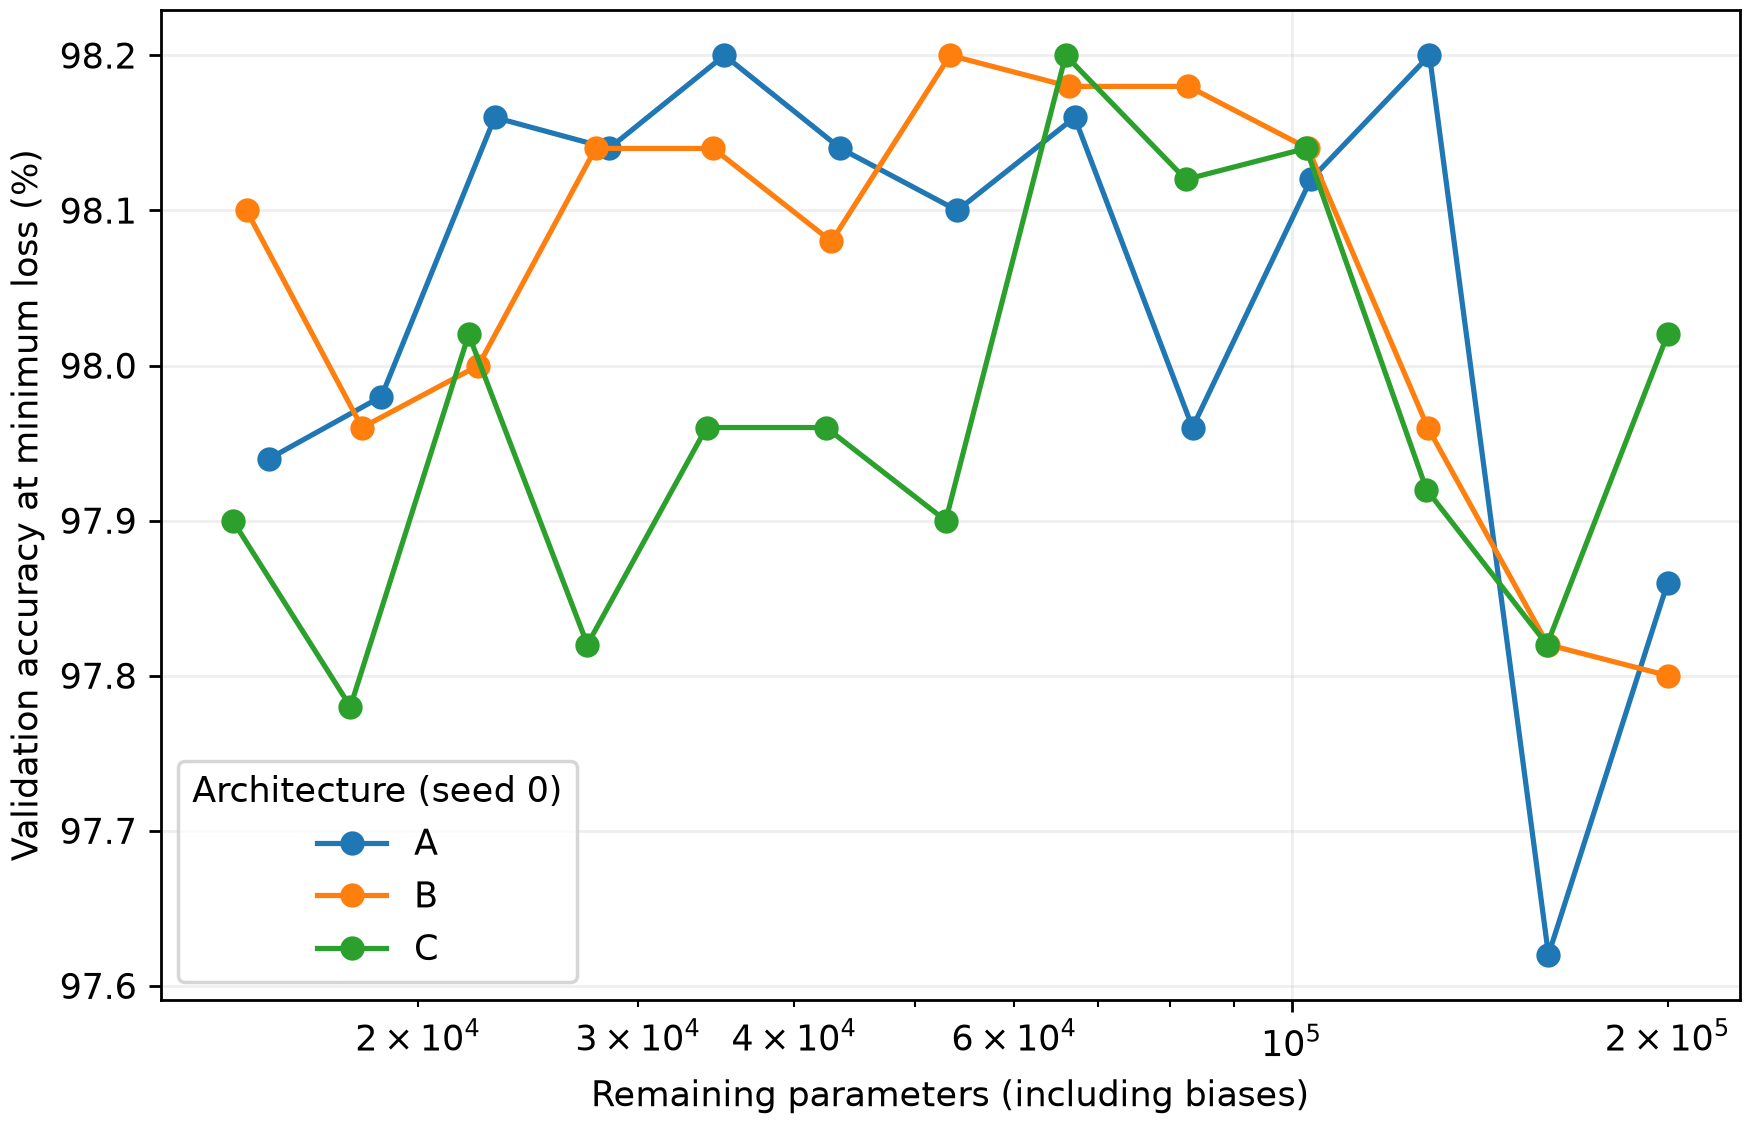

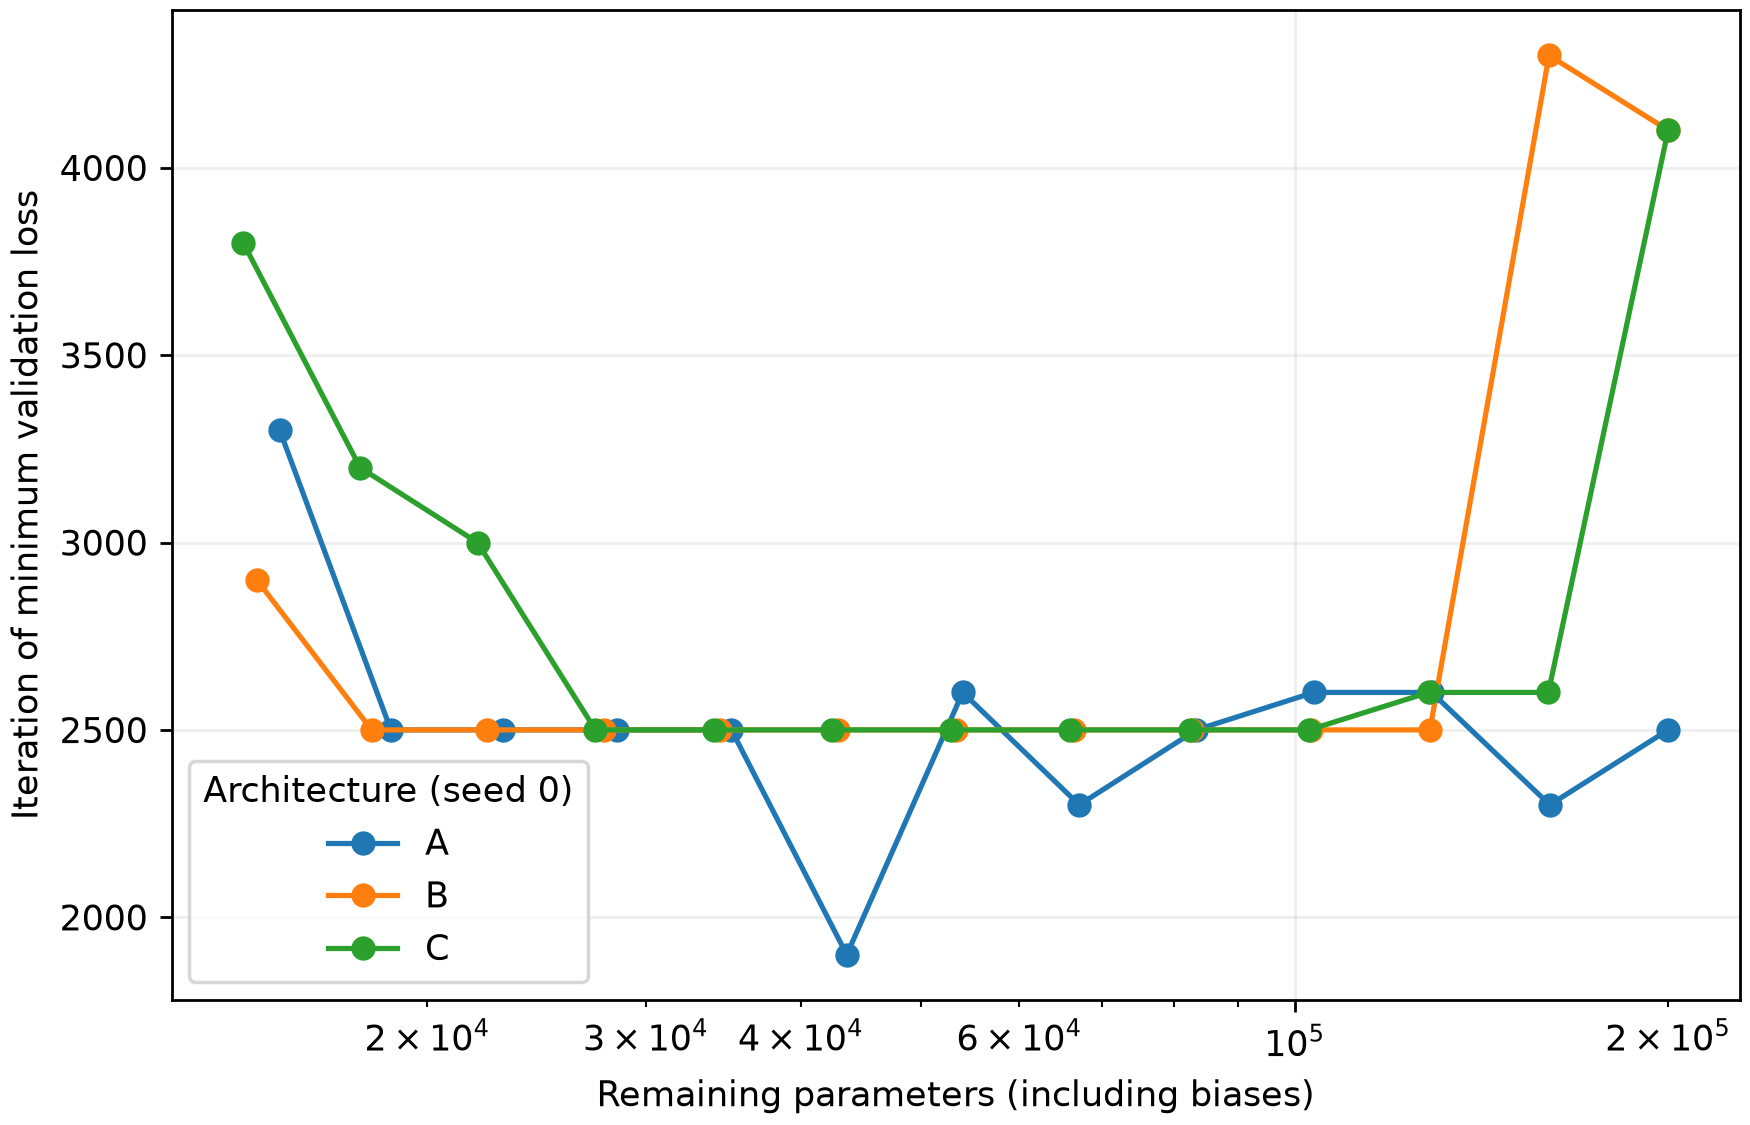

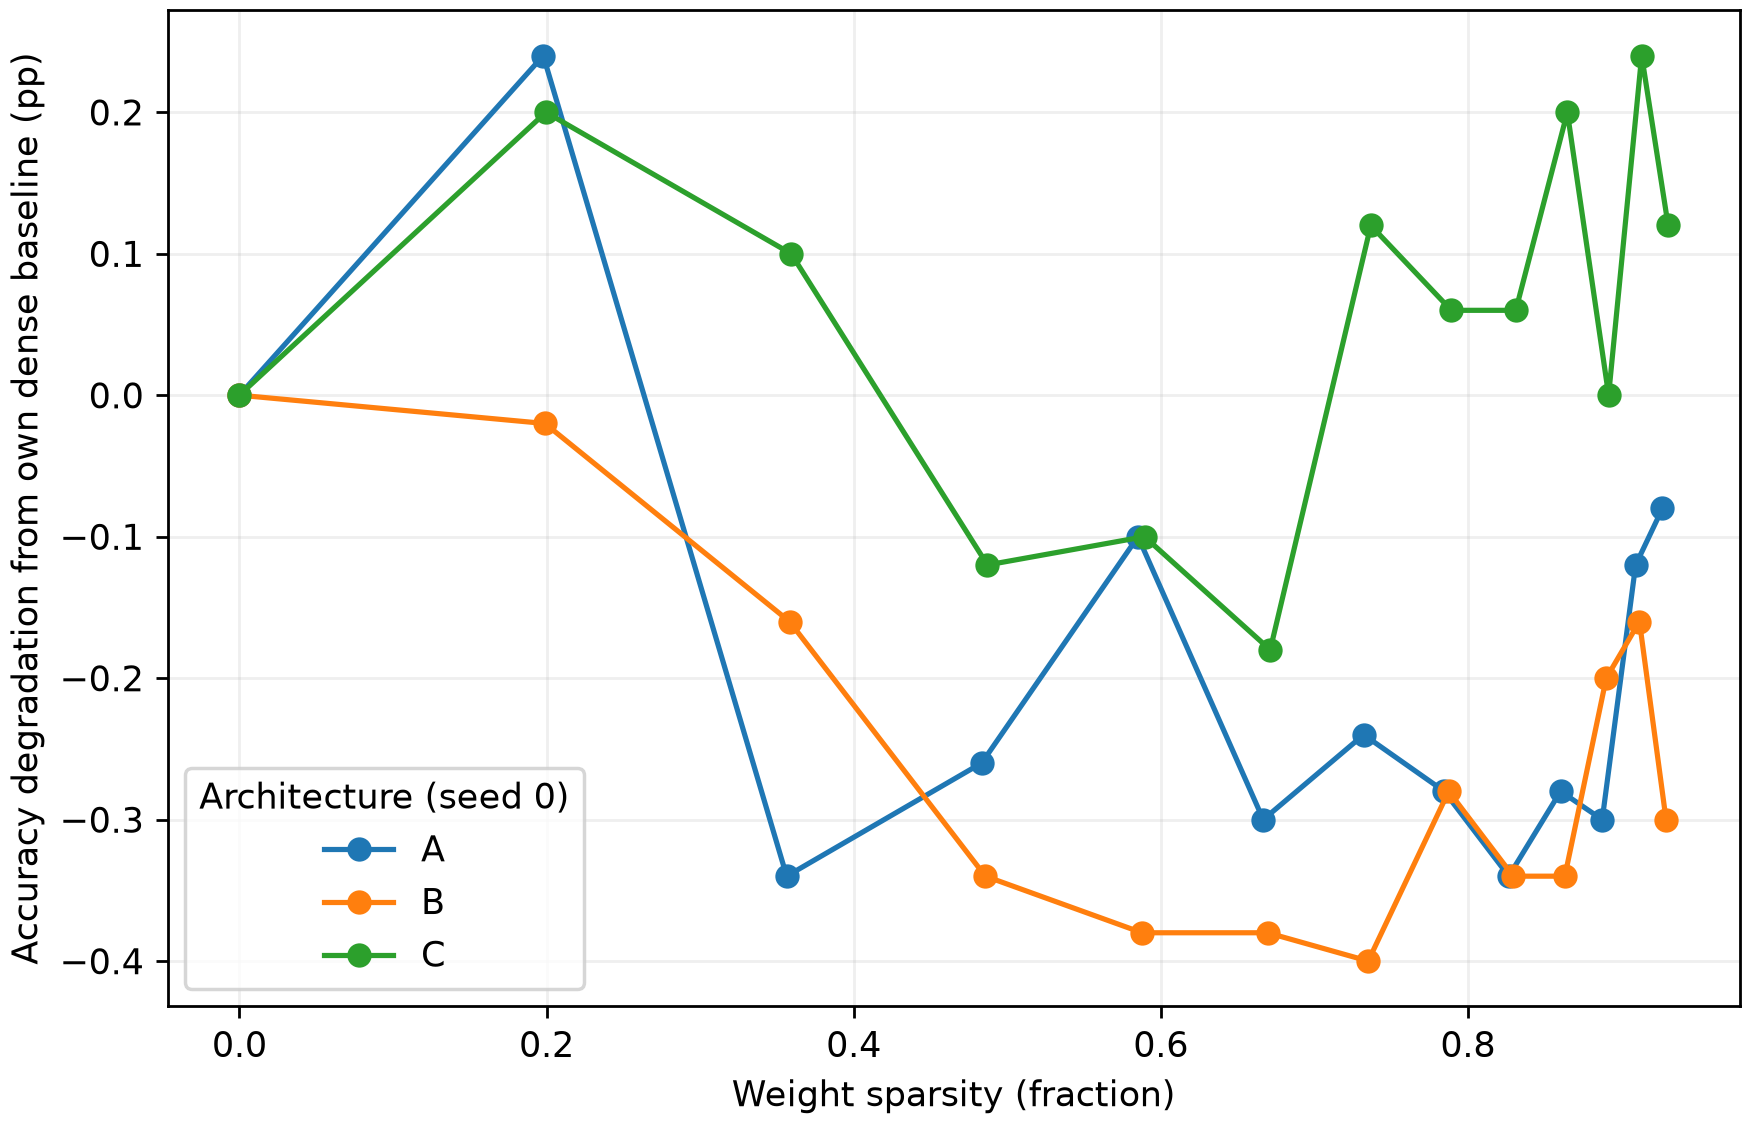

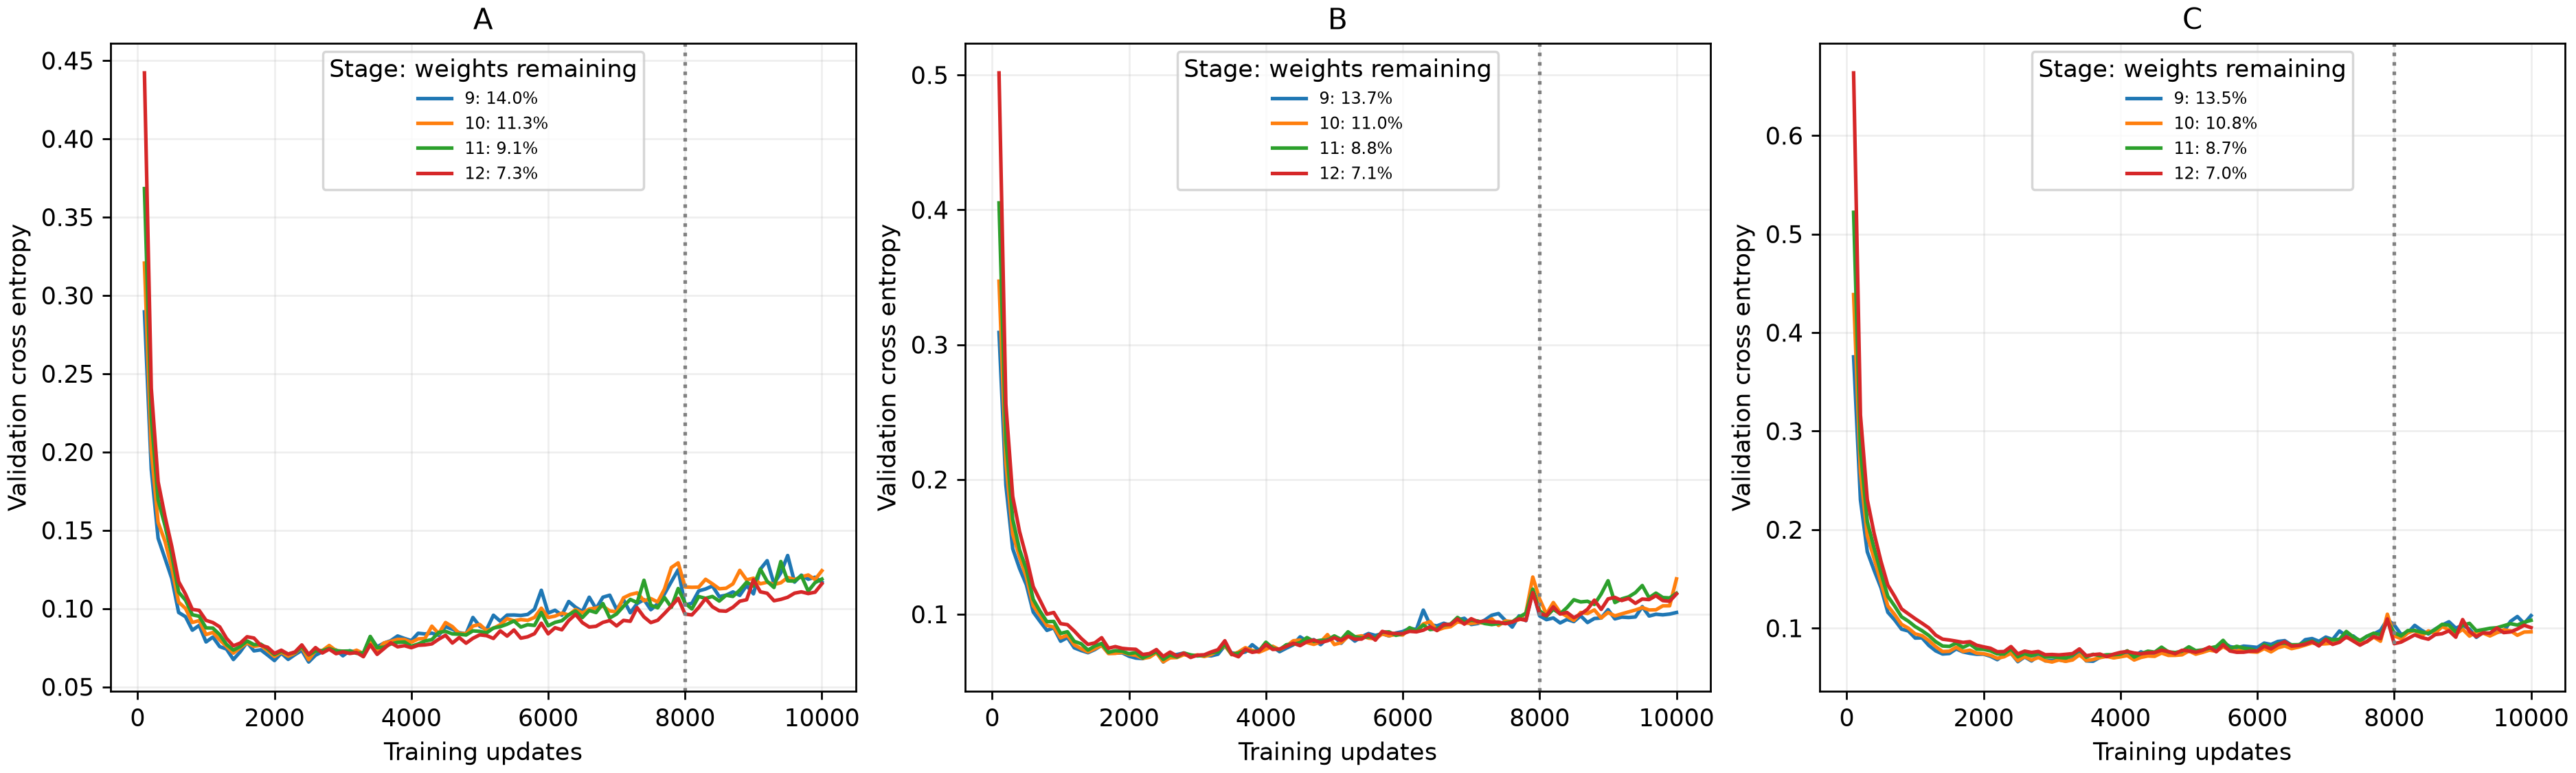

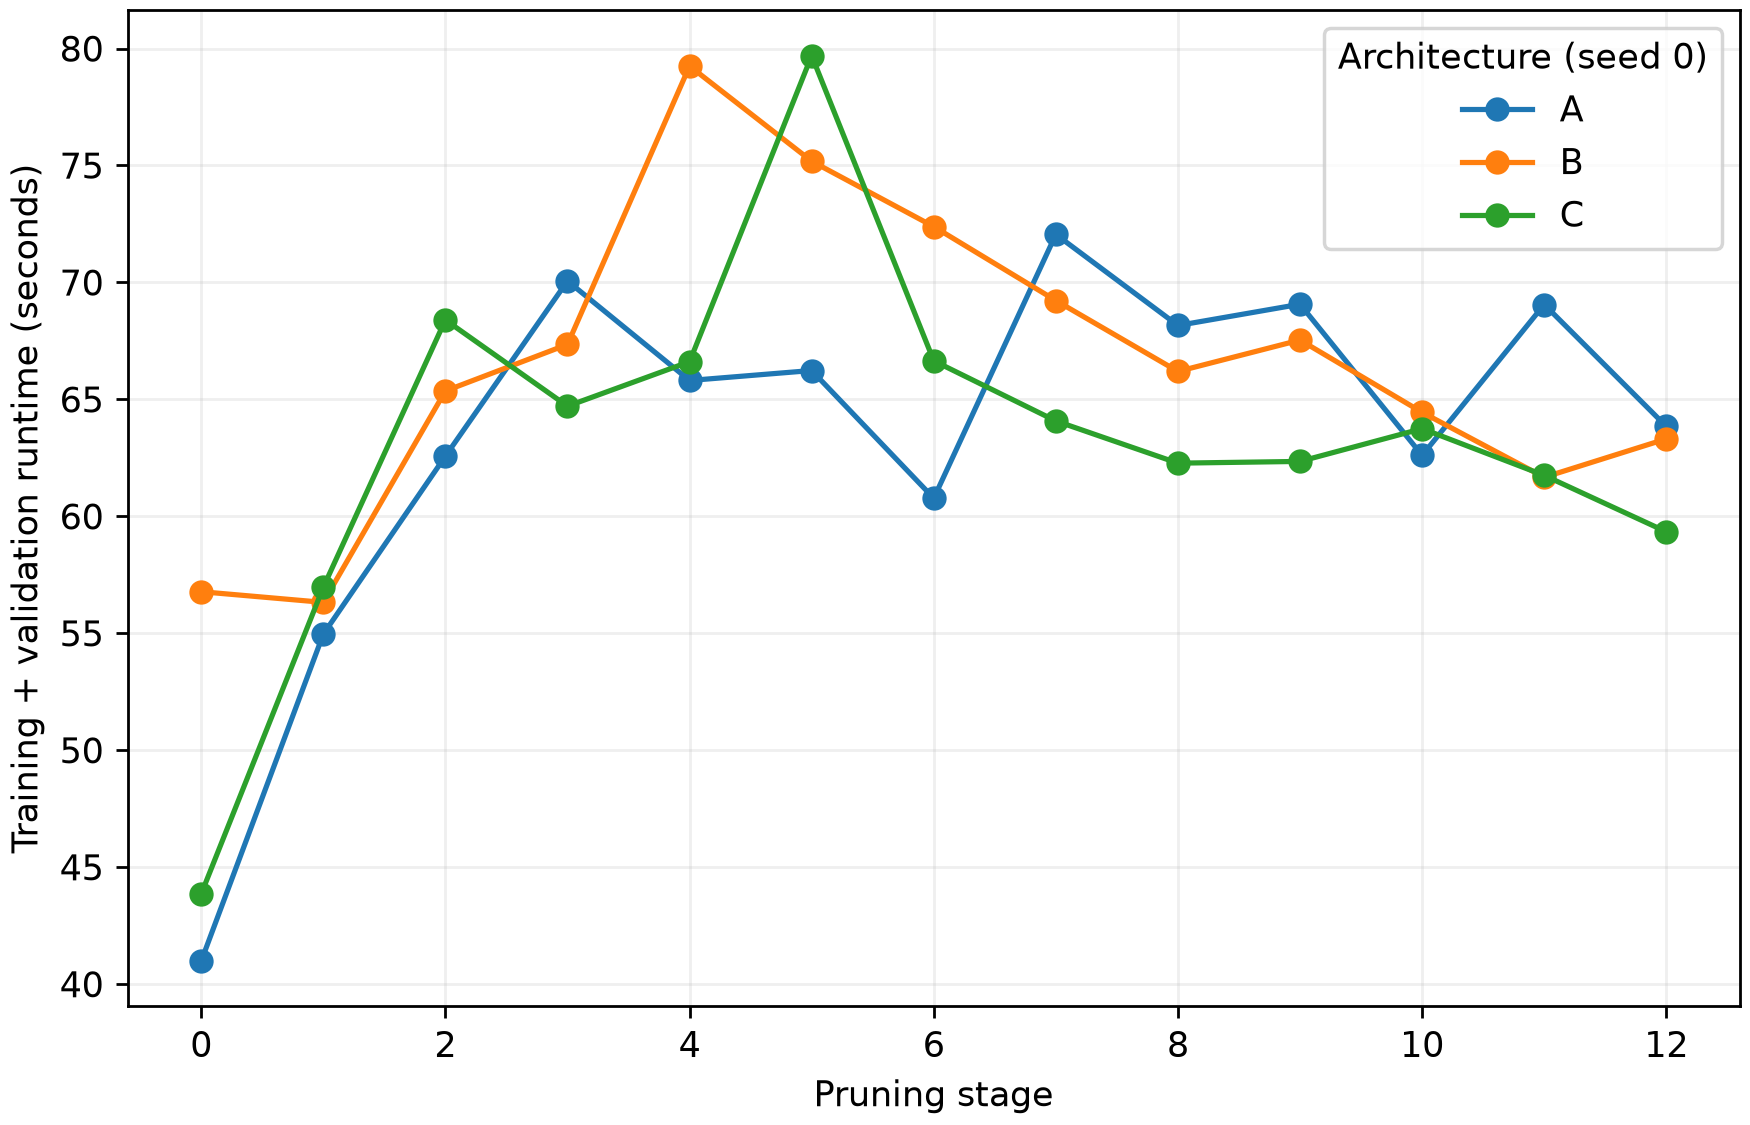

In [5]:
import importlib, stage2_6_analysis
importlib.reload(stage2_6_analysis)
from stage2_6_analysis import collect_comparison, save_figures, write_assessment, verify_actual_checkpoints
results, history, summary, runtimes = collect_comparison()
save_figures(results, history)
display(summary)
display(runtimes)
display(results[["architecture", "stage", "remaining_parameters", "best_iteration",
    "best_validation_loss", "best_validation_accuracy", "accuracy_degradation_pp",
    "late_loss_slope_per_1000", "late_loss_decreasing", "budget_concern"]])
for name in ("accuracy_vs_remaining_parameters", "best_iteration_vs_remaining_parameters",
             "accuracy_degradation_vs_sparsity", "high_sparsity_loss_curves", "runtime_by_stage"):
    display(Image(filename=str(REPORT / "figures" / f"{name}.png")))

In [6]:
verification = verify_actual_checkpoints()
display(verification)
final_tests = subprocess.run([sys.executable, "-m", "pytest", "-q"], capture_output=True, text=True)
(REPORT / "tests.txt").write_text(final_tests.stdout + final_tests.stderr)
print(final_tests.stdout)
final_tests.check_returncode()
assessment = write_assessment(results, history, summary, runtimes)
display(Markdown(assessment))

{'A': {'stages_verified': 13,
  'final_weight_pruning': True,
  'original_weight_restoration': True,
  'masks_enforced': True,
  'checkpoints_unchanged': True,
  'complete_resume_skips_training': True},
 'B': {'stages_verified': 13,
  'final_weight_pruning': True,
  'original_weight_restoration': True,
  'masks_enforced': True,
  'checkpoints_unchanged': True,
  'complete_resume_skips_training': True},
 'C': {'stages_verified': 13,
  'final_weight_pruning': True,
  'original_weight_restoration': True,
  'masks_enforced': True,
  'checkpoints_unchanged': True,
  'complete_resume_skips_training': 'C not resumed or trained'},
 'preservation': {'stage2_5_files_unchanged': True, 'files_verified': 319}}

..............................................................           [100%]
62 passed in 7.06s



# Stage 2.6 assessment

**Recommend 10,000 fixed updates per stage for all A/B/C in Stage 3, with primary validation every 100 updates, subject to your review.** All three seed-0 pilots covered their observed validation-loss minima before the final 20% of the budget, and no stage met the predefined late-training concern screen. There is no pilot evidence requiring a 15k/20k increase. This is supporting evidence from one seed per architecture, not a guarantee of convergence for every future seed.

**Stage 3 has not been started.** A and B were executed here with seed 0, 13 stages each and 10,000 fixed updates per stage. C was reused from all 1,300 recorded Stage 2.5 fine-grid observations and not retrained. All 39 stages use primary selection every **100 updates**. No pruning, optimizer, initialization or architecture-specific budget changes were made.

## Comparable results

| Model | Dense accuracy | Stage 12 accuracy | Degradation (pp) | Best-iteration range | Late minima | Runtime (min) |
|---|---:|---:|---:|---:|---:|---:|
| A | 97.86% | 97.94% | -0.08 | 1,900–3,300 | 0/13 | 13.77 |
| B | 97.80% | 98.10% | -0.30 | 2,500–4,300 | 0/13 | 14.42 |
| C | 98.02% | 97.90% | +0.12 | 2,500–4,100 | 0/13 | 13.67 |

Accuracy is selected at the iteration of **minimum validation loss**, not maximum accuracy. Positive degradation means worse than that architecture's own fine-grid dense baseline. The final column is measured training+validation time, excluding loading/initialization/checkpoint/plot overhead; C's time is the original historical measurement including every-100 evaluations. Seed-0 curves have no between-seed error bars and do not establish statistical significance or a superior width ratio.

C's corrected dense accuracy is **98.02% at update 4,100**; stage 12 is **97.90%**, giving **+0.12 pp** degradation. The original 500-grid selections remain in source provenance columns and all Stage 2.5 files are unchanged. No C training time was newly incurred here.

## Budget and late-training evidence

- Loss minima in updates 8,000–10,000: **0/39**.
- Minima exactly at update 10,000: **0/39**.
- Late decreasing trends (both negative slope and negative mean change): **5/39**.
- Budget-concern flags: **0/39**, including **0** in highly pruned stages 9–12.

The screen is deliberately descriptive: flag a minimum in the last 20%, or a decreasing trend over updates 8,000–10,000 whose final loss is within 2% of the best observed loss. The slope is an ordinary linear fit (loss units per 1,000 updates). Mean change compares updates 9,100–10,000 with 8,000–8,900. These thresholds are heuristics, not formal convergence tests. A late decline well above an earlier global minimum can reflect fluctuation/overfitting recovery and is not by itself evidence that the budget is insufficient. Full per-stage losses and accuracies are in `validation_history.csv`; all derived measures and remaining parameter counts are in `results.csv` and `stage_diagnostics.csv`.

No targeted longer-training diagnostic is currently indicated by the screen. If later seeds show late minima, investigate saved masks before changing the common budget.

## Runtime

- Newly executed A+B training/evaluation: **28.19 minutes**.
- Total recorded seed-0 A+B+C training/evaluation (including reused C): **41.86 minutes**.
- Three architectures × three seeds × 13 stages × 10,000 updates: **117 stage trainings / 1,170,000 updates**. Projected serial CPU time: **2.09 hours**, or **2.62 hours** with a 25% planning allowance. Optional random-reinitialization controls are not included and would add work.

If the reviewed Stage 3 protocol remains exactly the same, all three validated seed-0 pilots can be reused. Only seeds 1 and 2 would then remain: **78 stage trainings / 780,000 new updates**, estimated **1.40 CPU hours**, or **1.74 hours** with allowance. This is conditional planning, not a launch or a claim that a new budget could reuse these masks.

The complete-study projection is three times the sum of the three measured seed-0 runtimes, rather than an assumption that parameter count predicts speed. Host load, seed-dependent variation and overhead add uncertainty; C was measured in the earlier stage. The allowance is not a statistical confidence interval. Runs use one CPU thread, exactly equivalent preloaded MNIST tensors, and dense matrix operations despite masking. GPU timings are unavailable and are not inferred. Native macOS/Windows/CUDA/MPS were not tested in this Linux CPU session.

## Verification and preservation

Final tests: **62 passed in 7.06s**. Every real stage checkpoint was checked against pruning its parent's final weights, original surviving initialization/biases and persistent zero masks. Completed A/B pilots were resumed with training forbidden to confirm no stages rerun. All **319 Stage 2.5 files** passed the before/after checksum comparison. The six core training/pruning/data/checkpoint source hashes, software versions and fixed split hash agree between A/B and reused C. The held-out test set was not evaluated.

All results, live histories, masks/checkpoints, verification evidence and PDF/PNG figures are saved under `reports/stage2_6/`. `stage2_6.ipynb` executes the A/B pilots (or resumes their commits) and performs this same comparison. The original source C files are referenced through new provenance metadata, not modified.

## Methodological limits

The pilot budgets are uniformly 10,000 rather than G.1's 50,000 updates. Retrospective evaluation frequency is restored to G.1's 100. The new widths are the intended extension at approximately equal initial total parameter counts; biases stay unpruned. Because output weights are pruned more slowly and output-layer widths differ, the same pruning round leaves slightly different total remaining counts across architectures. Compare curves on actual remaining parameter counts; the stage-12 summary is not an exactly parameter-matched comparison. A fixed new split, zero biases, [0,1] pixels and floor rounding remain the documented choices. Scientific budget adequacy is judged from validation behavior, not a training-loss stopping rule. Earlier minima do not justify ending a stage early: final fixed-budget weights still determine the next mask. One model seed cannot rule out later minima in other seeds or guarantee the paper's lottery-ticket conclusions.

## Per-stage observations

| Model | Stage | Weights remaining (%) | Minimum iteration | Loss at minimum | Accuracy at minimum | Late loss slope / 1k | Late mean change | Budget flag |
|---|---:|---:|---:|---:|---:|---:|---:|---|
| A | 0 | 100.00 | 2,500 | 0.07586 | 97.86% | +0.00800 | +0.00861 | False |
| A | 1 | 80.21 | 2,300 | 0.07153 | 97.62% | +0.00691 | +0.00782 | False |
| A | 2 | 64.36 | 2,600 | 0.06854 | 98.20% | +0.00164 | -0.00060 | False |
| A | 3 | 51.66 | 2,600 | 0.06697 | 98.12% | -0.00339 | -0.00663 | False |
| A | 4 | 41.48 | 2,500 | 0.06677 | 97.96% | +0.00241 | -0.00165 | False |
| A | 5 | 33.32 | 2,300 | 0.06797 | 98.16% | +0.00085 | -0.00428 | False |
| A | 6 | 26.79 | 2,600 | 0.06554 | 98.10% | +0.01404 | +0.01476 | False |
| A | 7 | 21.54 | 1,900 | 0.06609 | 98.14% | +0.00419 | +0.00557 | False |
| A | 8 | 17.33 | 2,500 | 0.06320 | 98.20% | -0.00001 | -0.00156 | False |
| A | 9 | 13.96 | 2,500 | 0.06583 | 98.14% | +0.00897 | +0.01283 | False |
| A | 10 | 11.25 | 2,500 | 0.06732 | 98.16% | +0.00349 | +0.00276 | False |
| A | 11 | 9.07 | 2,500 | 0.07034 | 97.98% | +0.00882 | +0.01140 | False |
| A | 12 | 7.33 | 3,300 | 0.06922 | 97.94% | +0.00752 | +0.00863 | False |
| B | 0 | 100.00 | 4,100 | 0.07528 | 97.80% | +0.00949 | +0.00799 | False |
| B | 1 | 80.10 | 4,300 | 0.06836 | 97.82% | +0.00582 | +0.00247 | False |
| B | 2 | 64.17 | 2,500 | 0.06563 | 97.96% | +0.00775 | +0.00292 | False |
| B | 3 | 51.42 | 2,500 | 0.06377 | 98.14% | +0.00415 | -0.00156 | False |
| B | 4 | 41.21 | 2,500 | 0.06001 | 98.18% | +0.00249 | -0.00127 | False |
| B | 5 | 33.04 | 2,500 | 0.06217 | 98.18% | -0.00079 | +0.00029 | False |
| B | 6 | 26.49 | 2,500 | 0.06092 | 98.20% | -0.00042 | -0.00366 | False |
| B | 7 | 21.25 | 2,500 | 0.06404 | 98.08% | -0.00051 | -0.00049 | False |
| B | 8 | 17.05 | 2,500 | 0.06281 | 98.14% | +0.00605 | +0.00688 | False |
| B | 9 | 13.68 | 2,500 | 0.06454 | 98.14% | +0.00267 | +0.00323 | False |
| B | 10 | 10.99 | 2,500 | 0.06473 | 98.00% | +0.00365 | +0.00364 | False |
| B | 11 | 8.83 | 2,500 | 0.06646 | 97.96% | +0.00733 | +0.00763 | False |
| B | 12 | 7.09 | 2,900 | 0.06791 | 98.10% | +0.00733 | +0.00915 | False |
| C | 0 | 100.00 | 4,100 | 0.07508 | 98.02% | +0.00947 | +0.01012 | False |
| C | 1 | 80.04 | 2,600 | 0.07451 | 97.82% | +0.00734 | +0.00404 | False |
| C | 2 | 64.07 | 2,600 | 0.07051 | 97.92% | +0.00576 | +0.00487 | False |
| C | 3 | 51.29 | 2,500 | 0.06503 | 98.14% | -0.00219 | -0.00483 | False |
| C | 4 | 41.06 | 2,500 | 0.06351 | 98.12% | +0.00894 | +0.01081 | False |
| C | 5 | 32.87 | 2,500 | 0.06351 | 98.20% | +0.00045 | +0.00124 | False |
| C | 6 | 26.32 | 2,500 | 0.06238 | 97.90% | +0.00283 | +0.00407 | False |
| C | 7 | 21.08 | 2,500 | 0.06264 | 97.96% | +0.01376 | +0.01201 | False |
| C | 8 | 16.88 | 2,500 | 0.06393 | 97.96% | +0.00237 | +0.00509 | False |
| C | 9 | 13.52 | 2,500 | 0.06597 | 97.82% | +0.00365 | +0.00125 | False |
| C | 10 | 10.83 | 3,000 | 0.06563 | 98.02% | +0.00092 | -0.00012 | False |
| C | 11 | 8.68 | 3,200 | 0.06970 | 97.78% | +0.00516 | +0.00501 | False |
| C | 12 | 6.96 | 3,800 | 0.07107 | 97.90% | +0.00655 | +0.00647 | False |


A fixed-mask longer-training diagnostic would retrain a selected saved mask from its original initialization with fresh Adam for 15k/20k updates, evaluating every 100, **without pruning again or changing any subsequent mask**. It diagnoses that particular ticket's training budget. It is not equivalent to rerunning the complete IMP chain at a longer fixed budget, which can produce different masks. Any eventual budget change for Stage 3 must apply uniformly to all architectures. No three-seed Stage 3 runs are started here.